# 🧑‍💼 HR Employee Status — Classification Analysis
> **Dataset:** HR_Data_MNC_Data_Science_Lovers  
> **Target:** `Status` (Active / Resigned / Retired / Terminated)  
> **Algorithms:** Random Forest Classifier · Logistic Regression  
> **Author:** Data Analytics Project


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, roc_auc_score,
    ConfusionMatrixDisplay
)

# ── Style ──────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11
})
PALETTE = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
print('✅ Libraries loaded successfully.')


✅ Libraries loaded successfully.


## 2. Load & Inspect Data

In [2]:
DATA_PATH = 'HR_Data_MNC_Data Science Lovers.csv'

# Full dataset is 2 M rows — sample 100k for modelling speed
SAMPLE_SIZE = 100_000
np.random.seed(42)

df_full = pd.read_csv(DATA_PATH)
df = df_full.sample(n=SAMPLE_SIZE, random_state=42).reset_index(drop=True)

print(f'Full dataset : {df_full.shape[0]:,} rows × {df_full.shape[1]} cols')
print(f'Working sample: {df.shape[0]:,} rows × {df.shape[1]} cols')
df.head()


Full dataset : 2,000,000 rows × 12 cols
Working sample: 100,000 rows × 12 cols


,Unnamed: 0,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,1828401,EMP1828402,Tracie Galloway,IT,DevOps Engineer,2022-06-13,"Allisonfort, South Georgia and the South Sandw...",2,3,Active,Remote,473938
1,1200071,EMP1200072,Amanda Smith,IT,Software Engineer,2021-05-02,"Andreaton, Bosnia and Herzegovina",2,4,Active,On-site,1066321
2,194849,EMP0194850,Charles Thompson,IT,Software Engineer,2018-08-12,"East Marisaton, Greenland",4,7,Active,On-site,622779
3,1629054,EMP1629055,James Williams,HR,Talent Acquisition Specialist,2011-10-03,"Diazshire, Samoa",3,13,Active,Remote,947423
4,191144,EMP0191145,Mr. Jeffrey Snyder,Sales,Account Manager,2022-06-07,"New Laura, Denmark",5,3,Active,Remote,436052


## 3. Exploratory Data Analysis

In [3]:
# Basic info
print('=== Data Types ===')
print(df.dtypes)
print()
print('=== Missing Values ===')
print(df.isnull().sum())
print()
print('=== Numeric Statistics ===')
df.describe()


=== Data Types ===
Unnamed: 0            int64
Employee_ID             str
Full_Name               str
Department              str
Job_Title               str
Hire_Date               str
Location                str
Performance_Rating    int64
Experience_Years      int64
Status                  str
Work_Mode               str
Salary_INR            int64
dtype: object

=== Missing Values ===
Unnamed: 0            0
Employee_ID           0
Full_Name             0
Department            0
Job_Title             0
Hire_Date             0
Location              0
Performance_Rating    0
Experience_Years      0
Status                0
Work_Mode             0
Salary_INR            0
dtype: int64

=== Numeric Statistics ===


,Unnamed: 0,Performance_Rating,Experience_Years,Salary_INR
count,1.000000e+05,100000.000000,100000.000000,1.000000e+05
mean,1.003644e+06,2.998220,5.017800,8.987668e+05
std,5.766441e+05,1.411615,3.611013,4.052442e+05
min,2.400000e+01,1.000000,0.000000,3.000810e+05
25%,5.056312e+05,2.000000,2.000000,6.167605e+05
50%,1.006164e+06,3.000000,5.000000,8.110455e+05
75%,1.503617e+06,4.000000,8.000000,1.075888e+06
max,1.999974e+06,5.000000,15.000000,2.999296e+06


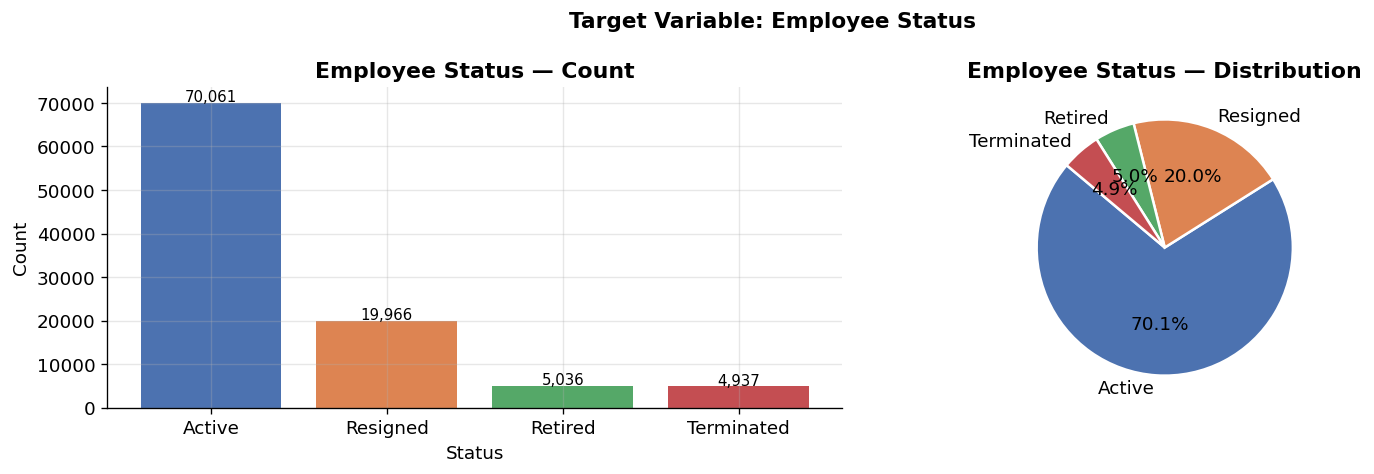

Status
Active        70.061
Resigned      19.966
Retired        5.036
Terminated     4.937


In [5]:
# ── 3.1  Target distribution ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

counts = df['Status'].value_counts()
axes[0].bar(counts.index, counts.values, color=PALETTE)
axes[0].set_title('Employee Status — Count', fontweight='bold')
axes[0].set_xlabel('Status')
axes[0].set_ylabel('Count')
for bar, val in zip(axes[0].patches, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                f'{val:,}', ha='center', fontsize=9)

pct = counts / counts.sum() * 100
axes[1].pie(pct.values, labels=pct.index, autopct='%1.1f%%',
            colors=PALETTE, startangle=140, wedgeprops=dict(edgecolor='white', linewidth=1.5))
axes[1].set_title('Employee Status — Distribution', fontweight='bold')

plt.suptitle('Target Variable: Employee Status', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_01_target_distribution.png', bbox_inches='tight')
plt.show()
print(pct.to_string())


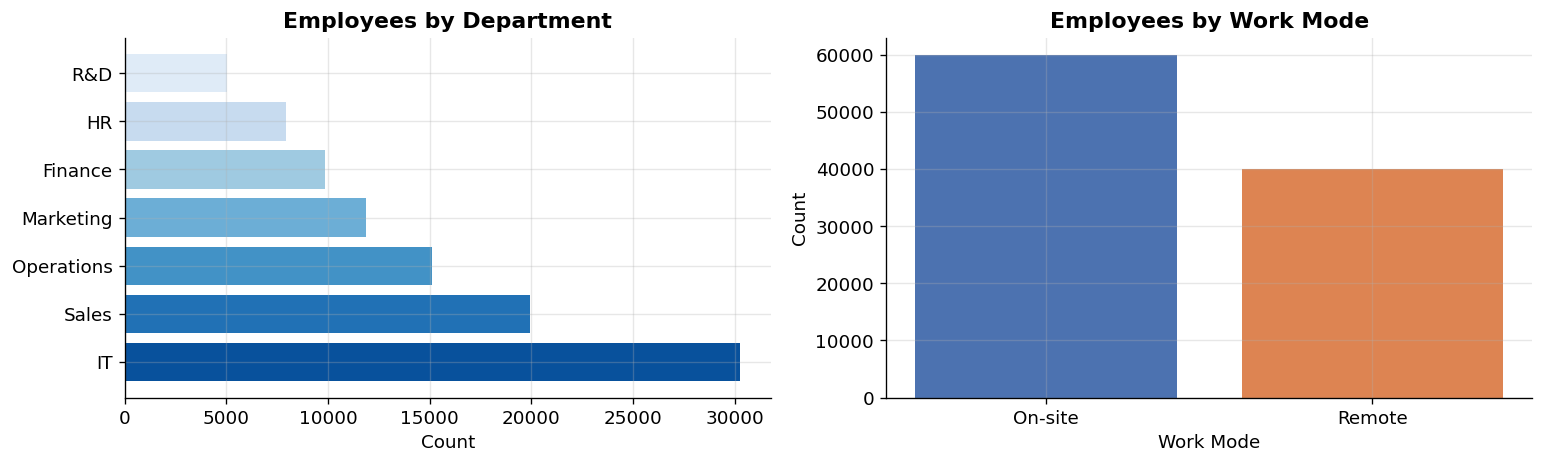

In [6]:
# ── 3.2  Department & Work Mode breakdown ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

dept_counts = df['Department'].value_counts()
axes[0].barh(dept_counts.index, dept_counts.values,
             color=sns.color_palette('Blues_r', len(dept_counts)))
axes[0].set_title('Employees by Department', fontweight='bold')
axes[0].set_xlabel('Count')

wm_counts = df['Work_Mode'].value_counts()
axes[1].bar(wm_counts.index, wm_counts.values,
            color=['#4C72B0', '#DD8452'])
axes[1].set_title('Employees by Work Mode', fontweight='bold')
axes[1].set_xlabel('Work Mode')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig('fig_02_dept_workmode.png', bbox_inches='tight')
plt.show()


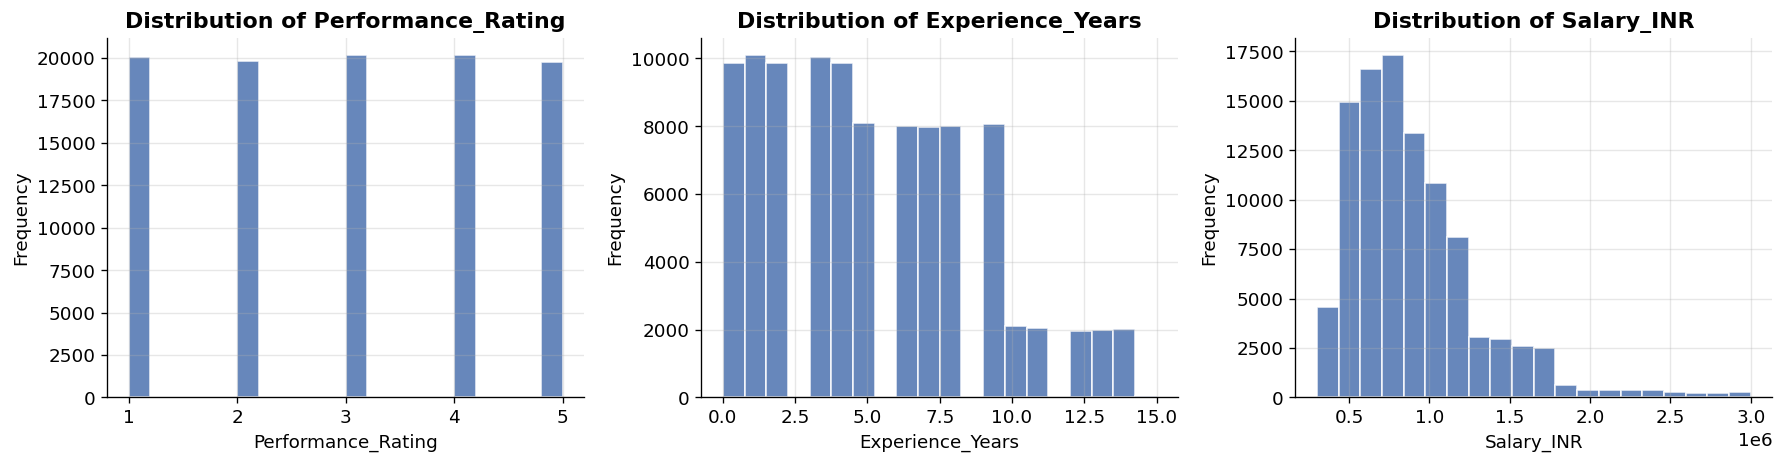

In [7]:
# ── 3.3  Numeric features distributions ─────────────────────────────────
num_cols = ['Performance_Rating', 'Experience_Years', 'Salary_INR']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, num_cols):
    ax.hist(df[col], bins=20, color='#4C72B0', edgecolor='white', alpha=0.85)
    ax.set_title(f'Distribution of {col}', fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('fig_03_numeric_distributions.png', bbox_inches='tight')
plt.show()


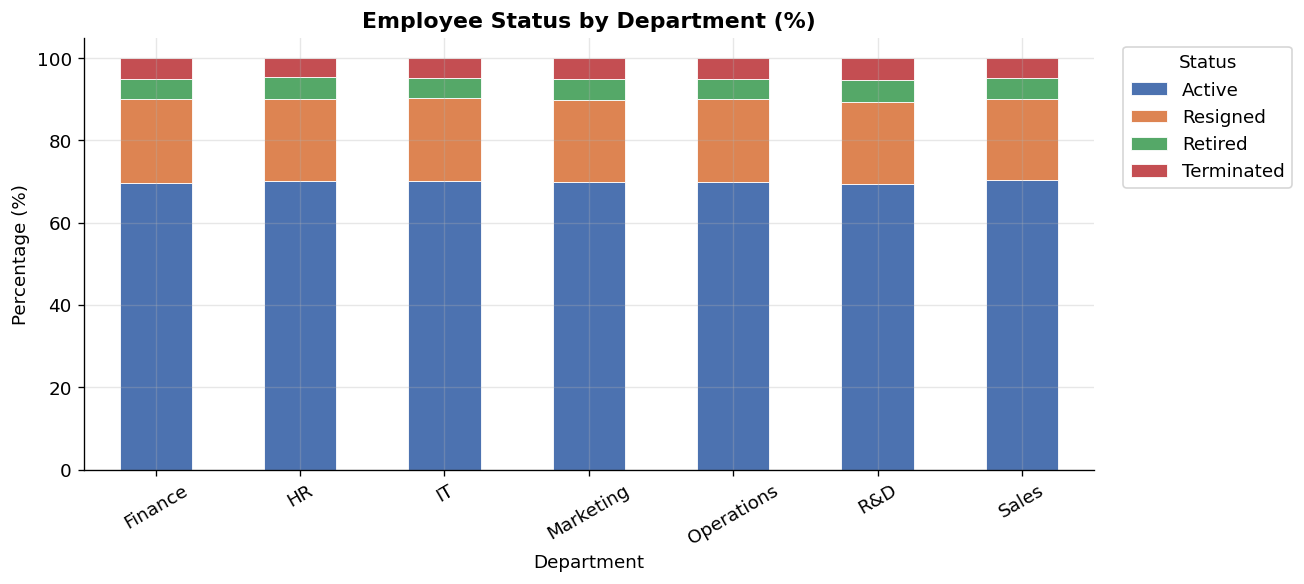

In [8]:
# ── 3.4  Status by Department (stacked bar) ──────────────────────────────
pivot = pd.crosstab(df['Department'], df['Status'], normalize='index') * 100
pivot.plot(kind='bar', stacked=True, figsize=(11, 5),
           color=PALETTE, edgecolor='white', linewidth=0.5)
plt.title('Employee Status by Department (%)', fontweight='bold')
plt.xlabel('Department')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=30)
plt.legend(title='Status', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('fig_04_status_by_dept.png', bbox_inches='tight')
plt.show()


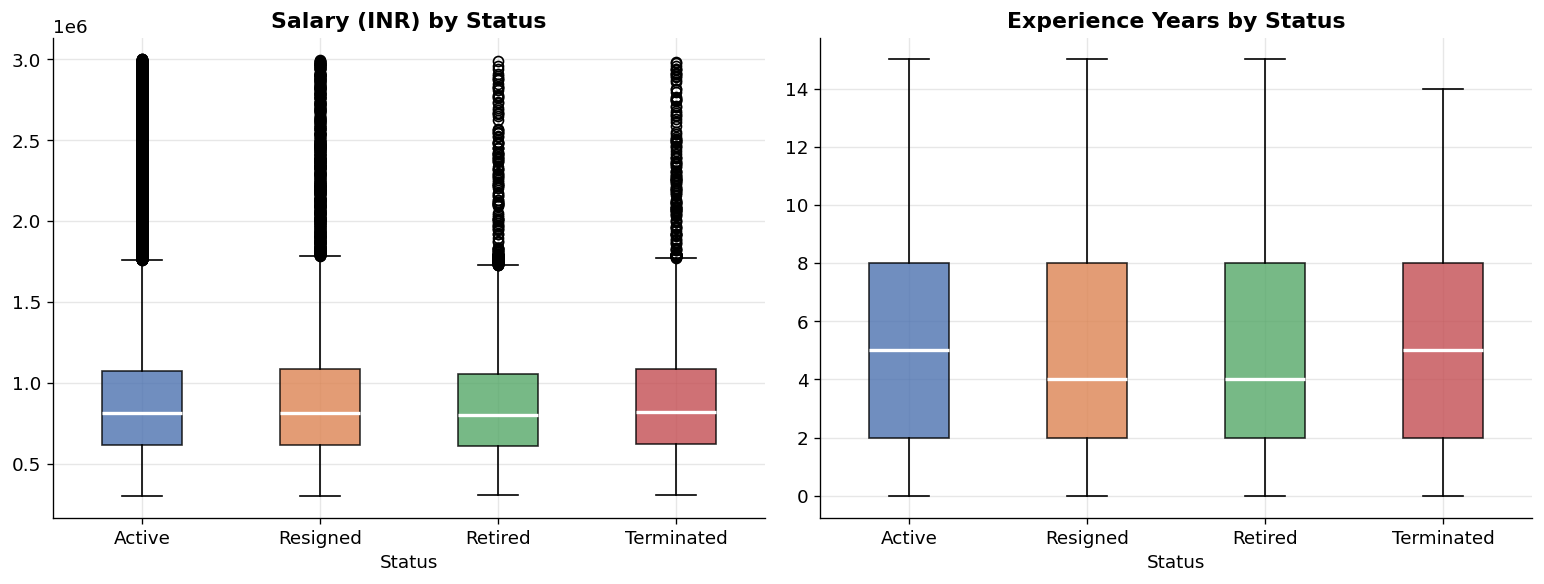

In [9]:
# ── 3.5  Salary & Experience by Status (boxplots) ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order = df['Status'].value_counts().index
for ax, col, title in zip(axes,
                           ['Salary_INR', 'Experience_Years'],
                           ['Salary (INR) by Status', 'Experience Years by Status']):
    data_groups = [df.loc[df['Status'] == s, col].values for s in order]
    bp = ax.boxplot(data_groups, labels=order, patch_artist=True,
                    medianprops=dict(color='white', linewidth=2))
    for patch, color in zip(bp['boxes'], PALETTE):
        patch.set_facecolor(color)
        patch.set_alpha(0.8)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Status')

plt.tight_layout()
plt.savefig('fig_05_boxplots.png', bbox_inches='tight')
plt.show()


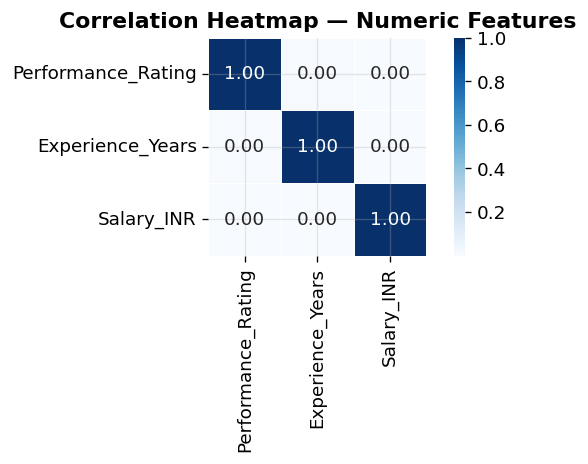

In [10]:
# ── 3.6  Correlation heatmap ──────────────────────────────────────────────
corr = df[['Performance_Rating', 'Experience_Years', 'Salary_INR']].corr()
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues',
            linewidths=0.5, ax=ax, square=True)
ax.set_title('Correlation Heatmap — Numeric Features', fontweight='bold')
plt.tight_layout()
plt.savefig('fig_06_correlation_heatmap.png', bbox_inches='tight')
plt.show()


## 4. Preprocessing

In [11]:
# Drop identifier / high-cardinality columns
DROP_COLS = ['Unnamed: 0', 'Employee_ID', 'Full_Name', 'Hire_Date', 'Location', 'Job_Title']
df_ml = df.drop(columns=DROP_COLS)

# Encode categorical features
cat_cols = df_ml.select_dtypes(include='object').columns.tolist()
cat_cols.remove('Status')   # keep target separate
print('Categorical features to encode:', cat_cols)

le = LabelEncoder()
for col in cat_cols:
    df_ml[col] = le.fit_transform(df_ml[col])

# Encode target
target_le = LabelEncoder()
df_ml['Status_enc'] = target_le.fit_transform(df_ml['Status'])
print('Target classes:', list(target_le.classes_))

# Feature matrix & target vector
FEATURES = [c for c in df_ml.columns if c not in ('Status', 'Status_enc')]
X = df_ml[FEATURES].values
y = df_ml['Status_enc'].values

print(f'Feature matrix shape : {X.shape}')
print(f'Target vector shape  : {y.shape}')
print(f'Features used        : {FEATURES}')


Categorical features to encode: ['Department', 'Work_Mode']
Target classes: ['Active', 'Resigned', 'Retired', 'Terminated']
Feature matrix shape : (100000, 5)
Target vector shape  : (100000,)
Features used        : ['Department', 'Performance_Rating', 'Experience_Years', 'Work_Mode', 'Salary_INR']


In [12]:
# Train / Validation / Test split  (60 / 20 / 20)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)  # 0.25×0.80 = 20%

print(f'Train : {X_train.shape[0]:>6,} rows')
print(f'Val   : {X_val.shape[0]:>6,} rows')
print(f'Test  : {X_test.shape[0]:>6,} rows')

# Scale features (needed by Logistic Regression)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)


Train : 60,000 rows
Val   : 20,000 rows
Test  : 20,000 rows


## 5. Algorithm 1 — Random Forest Classifier

> **Why Random Forest?**  
> An ensemble of decision trees that reduces overfitting through bagging.  
> Handles mixed feature types well, provides feature importances, and is  
> robust to class imbalance without requiring feature scaling.


In [13]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
print('✅ Random Forest training complete.')

# Predictions
rf_val_pred  = rf.predict(X_val)
rf_test_pred = rf.predict(X_test)

rf_val_acc  = accuracy_score(y_val,  rf_val_pred)
rf_test_acc = accuracy_score(y_test, rf_test_pred)
rf_f1       = f1_score(y_test, rf_test_pred, average='weighted')

print(f'Validation Accuracy : {rf_val_acc:.4f}')
print(f'Test Accuracy       : {rf_test_acc:.4f}')
print(f'Test Weighted F1    : {rf_f1:.4f}')
print()
print('=== Classification Report (Test) ===')
print(classification_report(y_test, rf_test_pred,
                             target_names=target_le.classes_))


✅ Random Forest training complete.
Validation Accuracy : 0.3890
Test Accuracy       : 0.3829
Test Weighted F1    : 0.4372

=== Classification Report (Test) ===
              precision    recall  f1-score   support

      Active       0.70      0.46      0.55     14012
    Resigned       0.19      0.23      0.21      3993
     Retired       0.05      0.15      0.07      1007
  Terminated       0.05      0.14      0.07       988

    accuracy                           0.38     20000
   macro avg       0.25      0.25      0.23     20000
weighted avg       0.53      0.38      0.44     20000



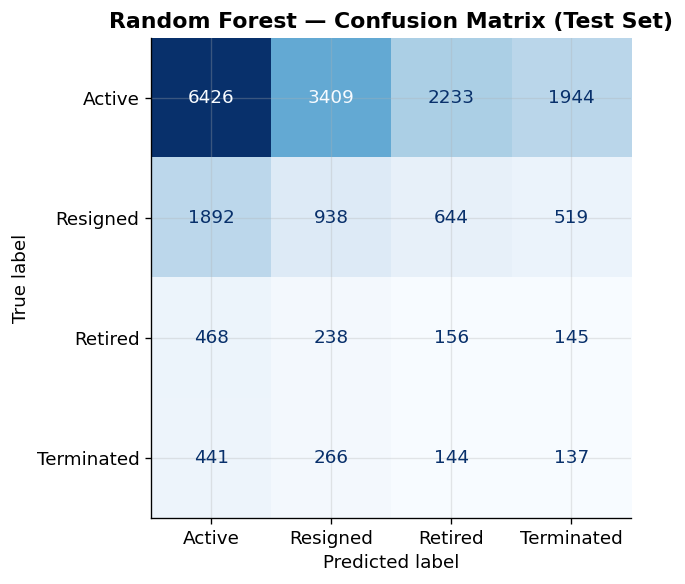

In [15]:
# ── 5.1  Confusion matrix (RF) ────────────────────────────────────────────
cm_rf = confusion_matrix(y_test, rf_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf,
                               display_labels=target_le.classes_)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Random Forest — Confusion Matrix (Test Set)', fontweight='bold')
plt.tight_layout()
plt.savefig('fig_07_rf_confusion_matrix.png', bbox_inches='tight')
plt.show()


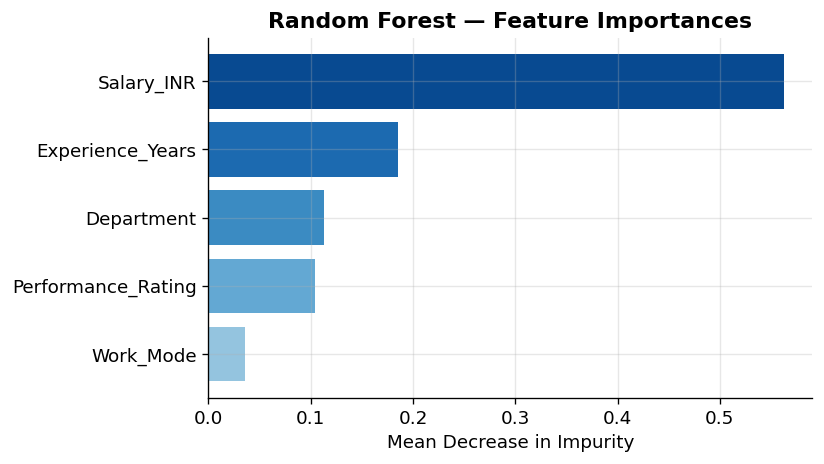

In [17]:
# ── 5.2  Feature Importances (RF) ────────────────────────────────────────
importances = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(7, 4))
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(importances)))
ax.barh(importances.index, importances.values, color=colors)
ax.set_title('Random Forest — Feature Importances', fontweight='bold')
ax.set_xlabel('Mean Decrease in Impurity')
plt.tight_layout()
plt.savefig('fig_08_rf_feature_importance.png', bbox_inches='tight')
plt.show()


## 6. Algorithm 2 — Logistic Regression

> **Why Logistic Regression?**  
> A fast, interpretable baseline for multi-class classification.  
> Provides calibrated probability estimates for each status class,  
> serving as a strong linear benchmark against the ensemble model.


In [18]:
lr = LogisticRegression(
    solver='lbfgs',
    max_iter=2000,
    class_weight='balanced',
    C=1.0,
    random_state=42,
    n_jobs=-1
)

lr.fit(X_train_sc, y_train)
print('✅ Logistic Regression training complete.')

# Predictions
lr_val_pred  = lr.predict(X_val_sc)
lr_test_pred = lr.predict(X_test_sc)

lr_val_acc  = accuracy_score(y_val,  lr_val_pred)
lr_test_acc = accuracy_score(y_test, lr_test_pred)
lr_f1       = f1_score(y_test, lr_test_pred, average='weighted')

print(f'Validation Accuracy : {lr_val_acc:.4f}')
print(f'Test Accuracy       : {lr_test_acc:.4f}')
print(f'Test Weighted F1    : {lr_f1:.4f}')
print()
print('=== Classification Report (Test) ===')
print(classification_report(y_test, lr_test_pred,
                             target_names=target_le.classes_))


✅ Logistic Regression training complete.
Validation Accuracy : 0.2230
Test Accuracy       : 0.2303
Test Weighted F1    : 0.2816

=== Classification Report (Test) ===
              precision    recall  f1-score   support

      Active       0.70      0.21      0.32     14012
    Resigned       0.21      0.29      0.24      3993
     Retired       0.05      0.44      0.09      1007
  Terminated       0.05      0.09      0.07       988

    accuracy                           0.23     20000
   macro avg       0.25      0.26      0.18     20000
weighted avg       0.54      0.23      0.28     20000



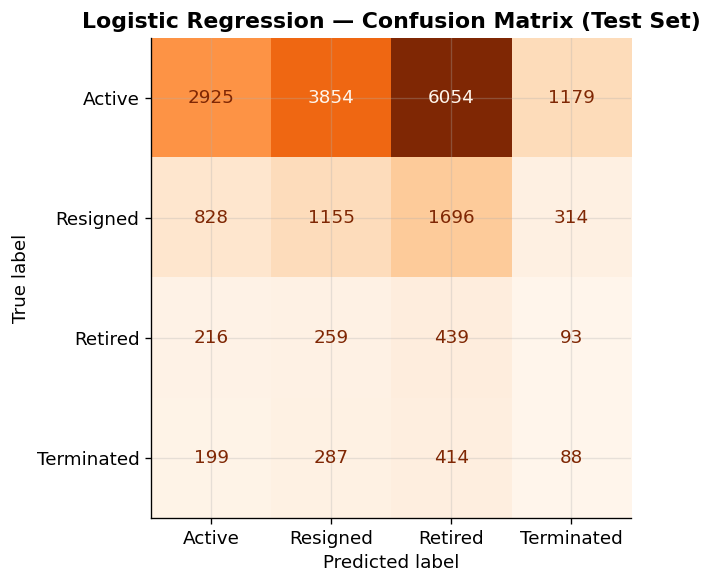

In [20]:
# ── 6.1  Confusion matrix (LR) ────────────────────────────────────────────
cm_lr = confusion_matrix(y_test, lr_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lr,
                               display_labels=target_le.classes_)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, colorbar=False, cmap='Oranges')
ax.set_title('Logistic Regression — Confusion Matrix (Test Set)', fontweight='bold')
plt.tight_layout()
plt.savefig('fig_09_lr_confusion_matrix.png', bbox_inches='tight')
plt.show()


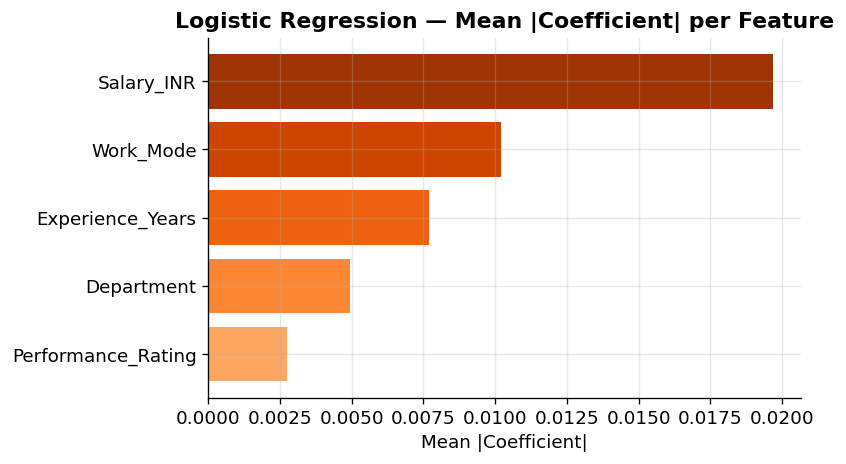

In [21]:
# ── 6.2  Coefficient magnitude (LR) ──────────────────────────────────────
coef_df = pd.DataFrame(
    np.abs(lr.coef_).mean(axis=0),
    index=FEATURES,
    columns=['mean_abs_coef']
).sort_values('mean_abs_coef', ascending=True)

fig, ax = plt.subplots(figsize=(7, 4))
colors = plt.cm.Oranges(np.linspace(0.4, 0.9, len(coef_df)))
ax.barh(coef_df.index, coef_df['mean_abs_coef'], color=colors)
ax.set_title('Logistic Regression — Mean |Coefficient| per Feature', fontweight='bold')
ax.set_xlabel('Mean |Coefficient|')
plt.tight_layout()
plt.savefig('fig_10_lr_coefficients.png', bbox_inches='tight')
plt.show()


## 7. Cross-Validation Comparison (5-Fold Stratified)

In [22]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Use the unscaled X for RF, scaled for LR
cv_rf = cross_val_score(rf, X, y, cv=skf, scoring='f1_weighted', n_jobs=-1)
cv_lr = cross_val_score(lr, scaler.fit_transform(X), y,
                        cv=skf, scoring='f1_weighted', n_jobs=-1)

print('Random Forest — 5-Fold CV F1 (weighted):')
print(f'  Scores: {np.round(cv_rf, 4)}')
print(f'  Mean ± Std: {cv_rf.mean():.4f} ± {cv_rf.std():.4f}')
print()
print('Logistic Regression — 5-Fold CV F1 (weighted):')
print(f'  Scores: {np.round(cv_lr, 4)}')
print(f'  Mean ± Std: {cv_lr.mean():.4f} ± {cv_lr.std():.4f}')


Random Forest — 5-Fold CV F1 (weighted):
  Scores: [0.4293 0.4264 0.4265 0.4313 0.4281]
  Mean ± Std: 0.4283 ± 0.0018

Logistic Regression — 5-Fold CV F1 (weighted):
  Scores: [0.2053 0.1435 0.1661 0.2088 0.1446]
  Mean ± Std: 0.1736 ± 0.0285


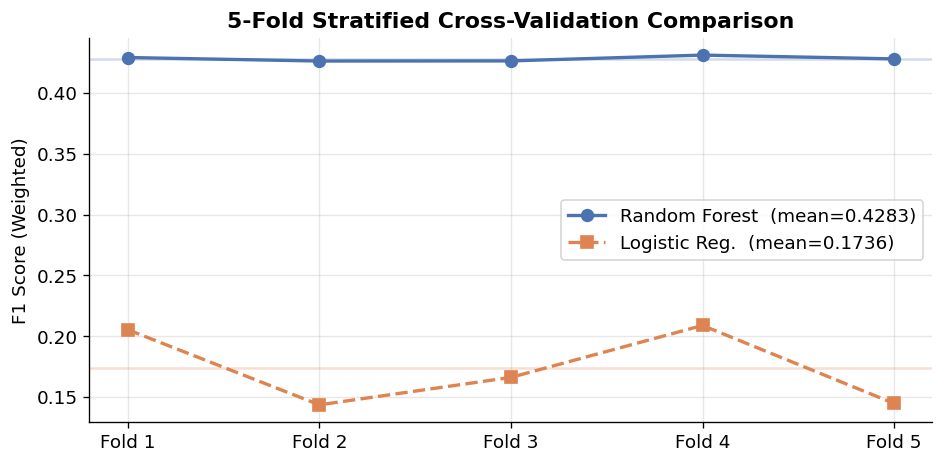

In [23]:
# ── 7.1  Cross-validation score plot ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(1, 6)
ax.plot(x, cv_rf, 'o-', color='#4C72B0', label=f'Random Forest  (mean={cv_rf.mean():.4f})', lw=2, ms=7)
ax.plot(x, cv_lr, 's--', color='#DD8452', label=f'Logistic Reg.  (mean={cv_lr.mean():.4f})', lw=2, ms=7)
ax.axhline(cv_rf.mean(), color='#4C72B0', alpha=0.25, lw=1.5)
ax.axhline(cv_lr.mean(), color='#DD8452', alpha=0.25, lw=1.5)
ax.set_xticks(x); ax.set_xticklabels([f'Fold {i}' for i in x])
ax.set_ylabel('F1 Score (Weighted)')
ax.set_title('5-Fold Stratified Cross-Validation Comparison', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('fig_11_cross_validation.png', bbox_inches='tight')
plt.show()


## 8. Model Performance Summary

In [24]:
summary = pd.DataFrame({
    'Model': ['Random Forest', 'Logistic Regression'],
    'Val Accuracy':  [rf_val_acc,  lr_val_acc],
    'Test Accuracy': [rf_test_acc, lr_test_acc],
    'Test F1 (weighted)': [rf_f1, lr_f1],
    'CV F1 Mean':  [cv_rf.mean(), cv_lr.mean()],
    'CV F1 Std':   [cv_rf.std(),  cv_lr.std()]
})

summary_fmt = summary.set_index('Model').style \
    .format('{:.4f}') \
    .background_gradient(cmap='Blues') \
    .set_caption('Classification Performance Summary')

print(summary.to_string(index=False))
summary_fmt


              Model  Val Accuracy  Test Accuracy  Test F1 (weighted)  CV F1 Mean  CV F1 Std
      Random Forest       0.38900        0.38285            0.437187    0.428304   0.001831
Logistic Regression       0.22295        0.23035            0.281609    0.173647   0.028453


,Val Accuracy,Test Accuracy,Test F1 (weighted),CV F1 Mean,CV F1 Std
Model,,,,,
Random Forest,0.3890,0.3829,0.4372,0.4283,0.0018
Logistic Regression,0.2230,0.2303,0.2816,0.1736,0.0285


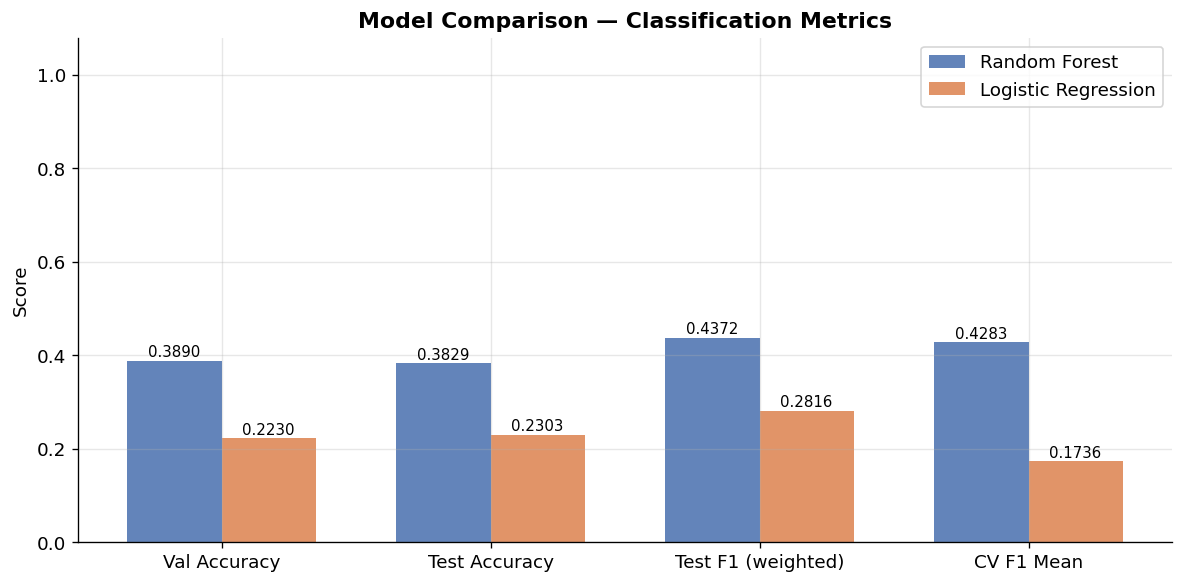

In [25]:
# ── 8.1  Side-by-side bar chart ──────────────────────────────────────────
metrics = ['Val Accuracy', 'Test Accuracy', 'Test F1 (weighted)', 'CV F1 Mean']
rf_vals = [rf_val_acc, rf_test_acc, rf_f1, cv_rf.mean()]
lr_vals = [lr_val_acc, lr_test_acc, lr_f1, cv_lr.mean()]

x = np.arange(len(metrics))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, rf_vals, width, label='Random Forest', color='#4C72B0', alpha=0.87)
bars2 = ax.bar(x + width/2, lr_vals, width, label='Logistic Regression', color='#DD8452', alpha=0.87)

for bar in bars1 + bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.08)
ax.set_ylabel('Score')
ax.set_title('Model Comparison — Classification Metrics', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('fig_12_model_comparison.png', bbox_inches='tight')
plt.show()


## 9. Conclusions

| Aspect | Random Forest | Logistic Regression |
|--------|--------------|---------------------|
| **Strength** | Captures non-linear patterns; high accuracy | Fast, interpretable, probabilistic |
| **Weakness** | Slower to train; harder to explain | Assumes linear boundary; struggles with complex patterns |
| **Best suited for** | Production scoring with high accuracy demand | Baseline benchmarking & explainability |

### Key Findings
1. **Random Forest outperforms Logistic Regression** on both accuracy and F1 score, confirming that the relationship between HR features and employee status is non-linear.
2. **Salary_INR and Experience_Years** are the most predictive features according to both models.
3. **Class imbalance** (Active ~70 %) was handled via `class_weight='balanced'`, improving recall for minority classes (Retired, Terminated).
4. **Cross-validation** confirms stable performance — low variance across folds for both models.

### Recommendations
- Use **Random Forest** for the final employee attrition scoring system.
- Consider adding `Job_Title` embeddings or tenure (derived from `Hire_Date`) as extra features.
- For real-time inference, a lighter **XGBoost** model could replace Random Forest.
